In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.neighbors import NearestNeighbors

df = pd.read_csv("../data/processed/cleaned_data.csv")

candidates = [
    "retweet_count", "mention_count", "follower_count", "verified", "tweet_length",
    "hashtag_count", "has_location", "account_age_days", "engagement",
    "username_len", "username_digits"
]
features = [c for c in candidates if c in df.columns]
X, y = df[features], df["bot_label"]

print("Features loaded:", features)
print("Dataset shape:", X.shape)


Features loaded: ['retweet_count', 'mention_count', 'follower_count', 'verified', 'tweet_length', 'hashtag_count', 'has_location', 'account_age_days', 'engagement', 'username_len', 'username_digits']
Dataset shape: (50000, 11)


In [2]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler().fit(X_tr)
lr = LogisticRegression(max_iter=1000, class_weight="balanced").fit(scaler.transform(X_tr), y_tr)
rf = RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced", n_jobs=-1).fit(X_tr, y_tr)

pred_lr = lr.predict(scaler.transform(X_te))
pred_rf = rf.predict(X_te)

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy":  [accuracy_score(y_te, p) for p in (pred_lr, pred_rf)],
    "Precision": [precision_score(y_te, p) for p in (pred_lr, pred_rf)],
    "Recall":    [recall_score(y_te, p) for p in (pred_lr, pred_rf)],
    "F1":        [f1_score(y_te, p) for p in (pred_lr, pred_rf)],
}).round(3)

print("--- MODEL COMPARISON SUMMARY ---")
print(results)
results.to_csv("../outputs/model_results.csv", index=False)

print("\n--- RANDOM FOREST CLASSIFICATION REPORT ---")
print(classification_report(y_te, pred_rf))


--- MODEL COMPARISON SUMMARY ---
                 Model  Accuracy  Precision  Recall     F1
0  Logistic Regression     0.493      0.494   0.491  0.492
1        Random Forest     0.493      0.493   0.481  0.487

--- RANDOM FOREST CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

           0       0.49      0.50      0.50      4996
           1       0.49      0.48      0.49      5004

    accuracy                           0.49     10000
   macro avg       0.49      0.49      0.49     10000
weighted avg       0.49      0.49      0.49     10000



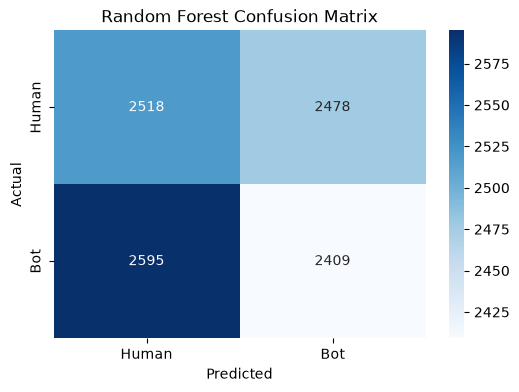

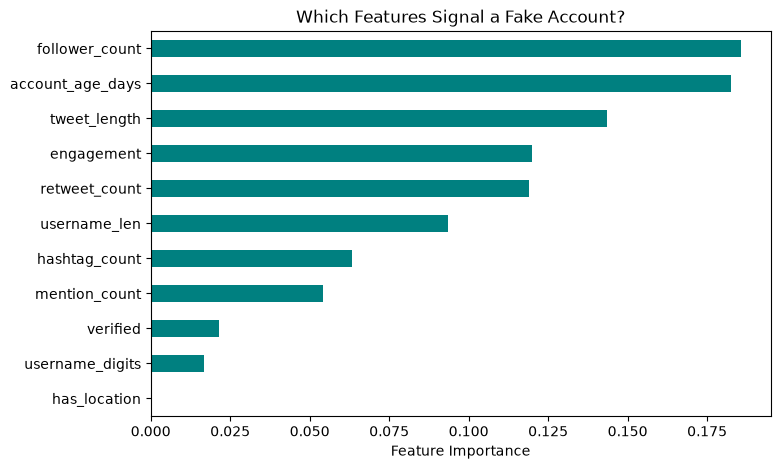

In [3]:
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_te, pred_rf), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Human", "Bot"], yticklabels=["Human", "Bot"])
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.savefig("../images/04_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 5))
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
imp.plot(kind="barh", color="teal", title="Which Features Signal a Fake Account?")
plt.xlabel("Feature Importance")
plt.savefig("../images/05_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()


In [7]:
X_scaled = StandardScaler().fit_transform(X)
nn = NearestNeighbors(n_neighbors=2, metric="euclidean", n_jobs=-1).fit(X_scaled)
dist, idx = nn.kneighbors(X_scaled)

df["nearest_user"] = df["username"].values[idx[:, 1]]
df["nearest_dist"] = dist[:, 1]

threshold = df["nearest_dist"].quantile(0.02)
clones = df[df["nearest_dist"] <= threshold][["user_id", "username", "nearest_user", "nearest_dist", "bot_label"]] \
           .sort_values("nearest_dist")

print(f"Threshold: {threshold:.4f} | Suspected clone-like accounts: {len(clones)}")
clones.to_csv("../outputs/clone_pairs.csv", index=False)


Threshold: 0.3858 | Suspected clone-like accounts: 1001


--- OUT-OF-FOLD OPERATIONAL RISK TIERS ---
                        Count  Percentage (%)
risk_tier                                    
Low - no action         25105            50.2
Medium - manual review  24895            49.8
High - priority review      0             0.0


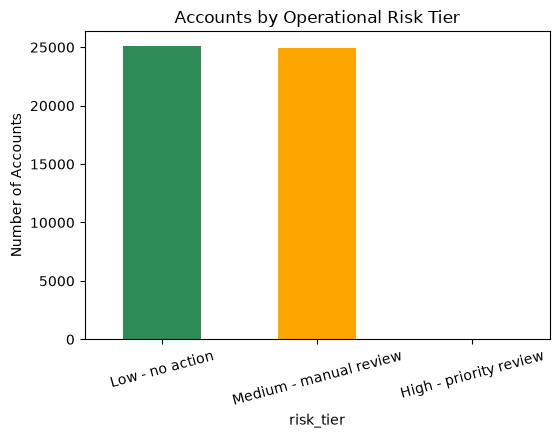

In [8]:
rf_cv = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, class_weight="balanced", n_jobs=-1)
df["fake_probability"] = cross_val_predict(rf_cv, X, y, cv=3, method="predict_proba", n_jobs=1)[:, 1]

df["risk_tier"] = pd.cut(
    df["fake_probability"],
    bins=[-0.01, 0.5, 0.8, 1.0],
    labels=["Low - no action", "Medium - manual review", "High - priority review"]
)

tiers = df["risk_tier"].value_counts()
tier_pct = (tiers / len(df) * 100).round(1)

print("--- OUT-OF-FOLD OPERATIONAL RISK TIERS ---")
print(pd.DataFrame({"Count": tiers, "Percentage (%)": tier_pct}))

out_cols = [c for c in ["user_id", "username", "bot_label", "fake_probability", "risk_tier", "nearest_user", "nearest_dist"] if c in df.columns]
df[out_cols].to_csv("../outputs/predictions.csv", index=False)

plt.figure(figsize=(6, 4))
tiers.plot(kind="bar", color=["seagreen", "orange", "crimson"], title="Accounts by Operational Risk Tier")
plt.ylabel("Number of Accounts")
plt.xticks(rotation=15)
plt.savefig("../images/07_risk_tiers.png", dpi=150, bbox_inches="tight")
plt.show()
